# Localización del tumor: verificación de la caja `sraw/eraw/scol/ecol`

**Por qué.** La CNN aprende la cohorte con AUC 0,998, pero ni el subtipo tumoral ni la pCR
(≈0,5): con la mama entera a 256 px ve el hospital, no el tumor. Para centrarla en el tumor
hace falta saber dónde está. La tabla de pacientes trae una caja (`sraw`, `eraw`, `scol`,
`ecol`), pero en el EDA no coincidía con la lesión.

**Hipótesis.** Las coordenadas están en el volumen original (`n_xy` píxeles de lado) y en
otra orientación. Se prueba girando la caja 90° y escalándola por `256 / n_xy`.

**Resultado** (detalle abajo): la caja girada 90° cae sobre la lesión en las tres cohortes
para `n_xy ≤ 320` (≈ 89 % de las pacientes). Para `n_xy` de 384 a 512 no cae.

In [1]:
import sys
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(REPO))

import torch  # noqa: F401  (antes que matplotlib: al reves el kernel muere en Windows)
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

from src import config
from src.data.tumor import caja_en_imagen

uc = config.utils()
pac = uc.cargar_patients().set_index("pid")
samples = uc.cargar_samples()
train = samples[samples.split == "train"].assign(
    cohorte=lambda d: d.patient_id.map(pac.dataset), n_xy=lambda d: d.patient_id.map(pac.n_xy))


def corte_central(pid):
    g = train[train.patient_id == pid]
    return g.iloc[len(g) // 2]


def dibujar(ax, pid, caja_original=True):
    """Realce EARLY-PRE sobre EARLY; rojo = caja tal cual, verde = caja_en_imagen."""
    f, p = corte_central(pid), pac.loc[pid]
    x = uc.cargar_imagen(f)
    realce = np.clip(x[1] - x[0], 0, None)
    ax.imshow(x[1], cmap="gray")
    ax.imshow(realce, cmap="hot", alpha=0.55, vmax=np.percentile(realce, 99.5))
    if caja_original:
        ax.add_patch(Rectangle((p.scol, p.sraw), p.ecol - p.scol, p.eraw - p.sraw, fill=False, ec="red", lw=1.5))
    caja = caja_en_imagen(p)
    if caja is not None:
        f0, f1, c0, c1 = caja
        ax.add_patch(Rectangle((c0, f0), c1 - c0, f1 - f0, fill=False, ec="lime", lw=1.5))
    ax.set_xlim(0, 256)
    ax.set_ylim(256, 0)
    ax.axis("off")
    ax.set_title(f"{p.dataset}  n_xy={int(p.n_xy)}  {pid[-6:]}", fontsize=9)

## 1. Pacientes con `n_xy = 256` (84 %)

Cinco pacientes al azar por cohorte. **Rojo:** la caja tal cual (lo que se probó en el EDA).
**Verde:** girada 90° (`filas = 256 − ecol … 256 − scol`, `columnas = sraw … eraw`).

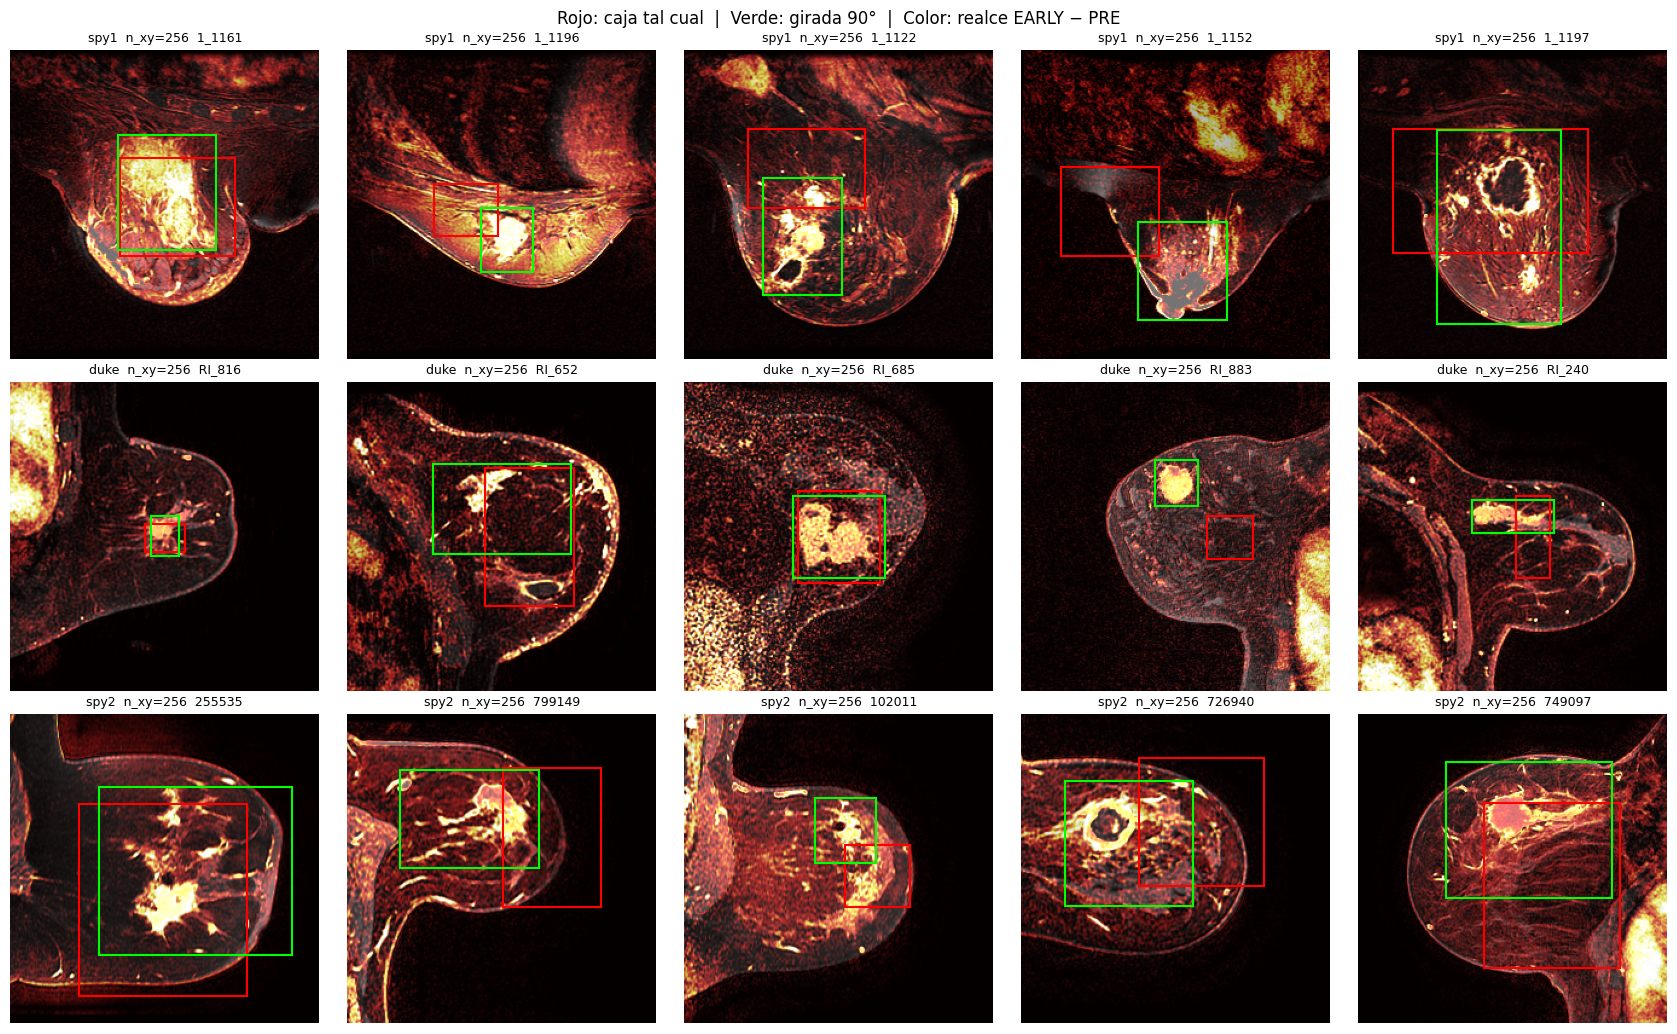

In [2]:
fig, ejes = plt.subplots(3, 5, figsize=(17, 10.5))
for fila, cohorte in zip(ejes, ("spy1", "duke", "spy2")):
    ids = train[(train.cohorte == cohorte) & (train.n_xy == 256)].patient_id.drop_duplicates()
    for ax, pid in zip(fila, ids.sample(5, random_state=1)):
        dibujar(ax, pid)
fig.suptitle("Rojo: caja tal cual  |  Verde: girada 90°  |  Color: realce EARLY − PRE")
fig.tight_layout()
fig.savefig(config.FIGURAS / "caja_tumor.png", dpi=110, facecolor="white")

La verde cae sobre la lesión que capta contraste en las tres cohortes; la roja, al lado.
Se repitió con otras muestras al azar (30 pacientes en total) con el mismo resultado.

## 2. Pacientes con otro tamaño original

Solo la caja verde, ya escalada por `256 / n_xy`. Para `n_xy > 320` la función devuelve
`None` (no se dibuja): se muestran con la caja escalada a mano para ver por qué se descarta.

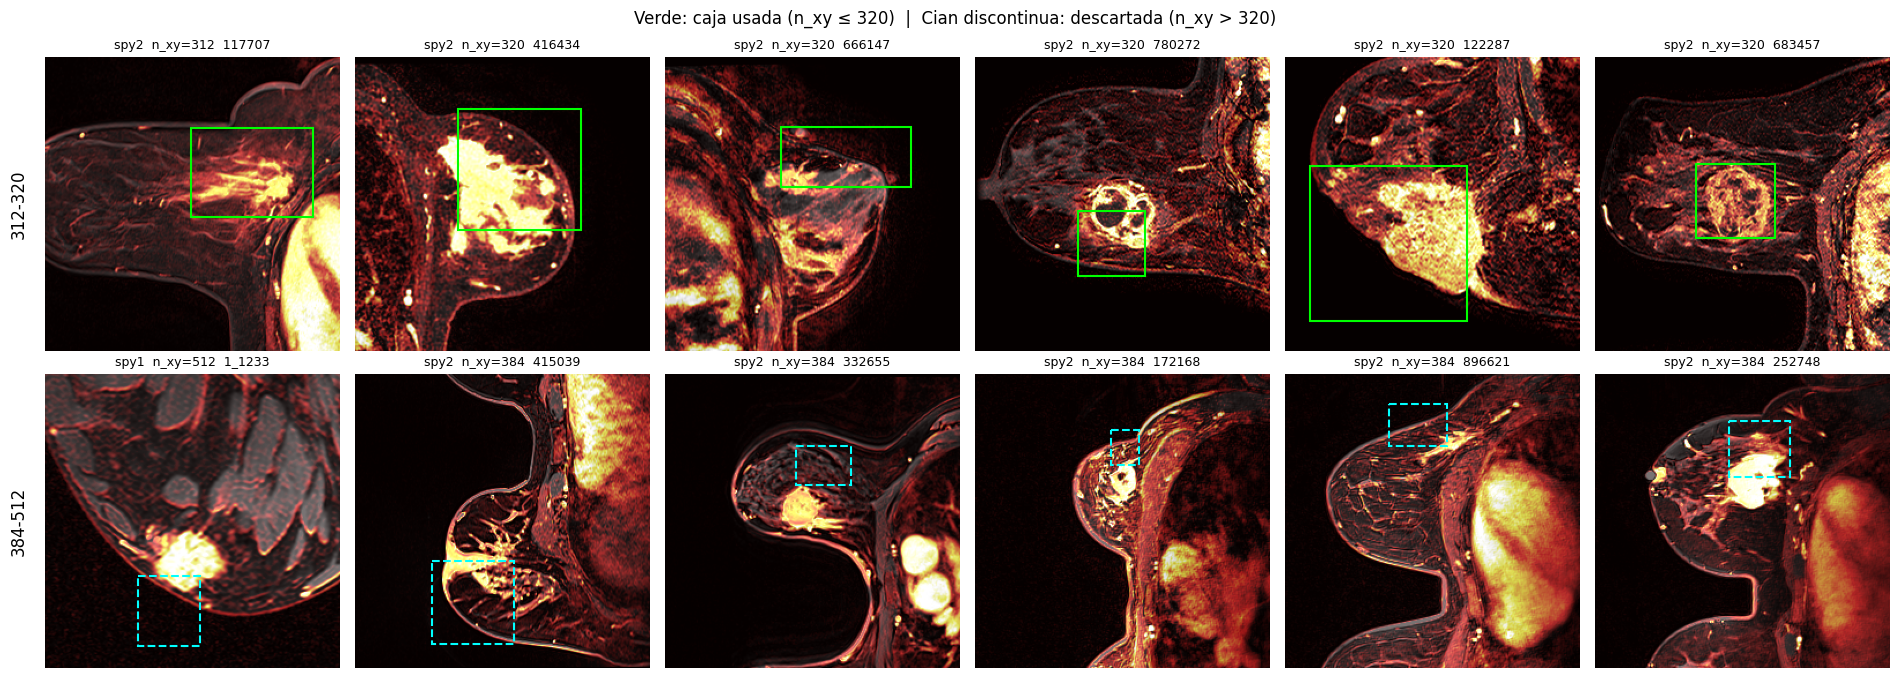

In [3]:
fig, ejes = plt.subplots(2, 6, figsize=(19, 7))
grupos = {"312-320": train[train.n_xy.between(312, 320)], "384-512": train[train.n_xy >= 384]}
for fila, (nombre, d) in zip(ejes, grupos.items()):
    for ax, pid in zip(fila, d.patient_id.drop_duplicates().sample(6, random_state=0)):
        dibujar(ax, pid, caja_original=False)
        p = pac.loc[pid]
        if caja_en_imagen(p) is None:          # dibujarla igualmente, en cian, para verla
            k = 256 / p.n_xy
            ax.add_patch(Rectangle((p.sraw * k, 256 - p.ecol * k), (p.eraw - p.sraw) * k,
                                   (p.ecol - p.scol) * k, fill=False, ec="cyan", lw=1.5, ls="--"))
    fila[0].text(-30, 128, nombre, rotation=90, va="center", fontsize=12)
fig.suptitle("Verde: caja usada (n_xy ≤ 320)  |  Cian discontinua: descartada (n_xy > 320)")
fig.tight_layout()
fig.savefig(config.FIGURAS / "caja_tumor_nxy.png", dpi=110, facecolor="white")

## 3. ¿Cuántas pacientes tienen una caja fiable?

In [4]:
pac["caja_fiable"] = [caja_en_imagen(p) is not None for _, p in pac.iterrows()]
tabla = pac.groupby(["split", "dataset"]).caja_fiable.agg(pacientes="size", con_caja="sum")
tabla["%"] = (100 * tabla.con_caja / tabla.pacientes).round(1)
tabla

pacientes  con_caja      %
split dataset                            
test  duke            42        42  100.0
      spy1            35        32   91.4
      spy2            99        87   87.9
train duke           209       208   99.5
      spy1           104        92   88.5
      spy2           784       672   85.7

## Conclusiones

- **La caja sí marca el tumor.** Está girada 90° respecto a los PNG y en la escala del
  volumen original. `src/data/tumor.py::caja_en_imagen` hace la conversión.
- **Fiable para `n_xy ≤ 320`**; para 384-512 (≈ 11 %, casi todas de spy2) no cae sobre la
  lesión y se descarta.
- **La caja no existe en la app.** En la defensa llegan solo las imágenes. Por tanto, la
  caja puede usarse para **entrenar** (o para un diagnóstico), pero el modelo final tiene
  que localizar el tumor por sí mismo.